lab6
\
jaber alsaikhan
\
2240006539

# ARTI 404 - Image Processing
## Lab 6: Frequency Domain

Outcome#1: Write a program that implements fundamental image processing
algorithms.

Both the procedural task and the assessment use the Cameraman image. Step 0
saves it from skimage's built-in sample data into `labs/lab6/images/` and the
rest of the notebook reads it from there, so the Lab 6 folder contains the
image the notebook uses.

In [1]:
import os

import numpy as np
import matplotlib.pyplot as plt

from numpy.fft import fft2, ifft2, fftshift, ifftshift
from scipy import ndimage
from skimage import data, io
from skimage.transform import resize

## Step 0: Prepare the working image on disk

In [2]:
# __file__ is undefined inside a notebook kernel, which starts in the notebook's
# own directory, so fall back to the working directory there.
try:
    HERE = os.path.dirname(os.path.abspath(__file__))
except NameError:
    HERE = os.getcwd()

IMAGES_DIR = os.path.join(HERE, "images")
os.makedirs(IMAGES_DIR, exist_ok=True)

CAMERAMAN_PATH = os.path.join(IMAGES_DIR, "cameraman.png")
io.imsave(CAMERAMAN_PATH, data.camera(), check_contrast=False)

print("Image:", os.path.basename(CAMERAMAN_PATH), io.imread(CAMERAMAN_PATH).shape)
print("Images dir:", os.path.normpath(IMAGES_DIR))

Image: cameraman.png (512, 512)
Images dir: c:\Users\jaber\OneDrive\Desktop\Image Processing\labs\lab6\images


## Task#1: Filtering in the Frequency Domain

The convolution theorem says that convolving an image with a filter in the
spatial domain is the same as multiplying their Fourier transforms:

`f * h  <->  F . H`

The continuous Laplacian `d2f/dx2 + d2f/dy2` has the frequency response
`H(u, v) = -4 pi^2 (u^2 + v^2)`. It is 0 at the DC term (u = v = 0) and grows
with the distance from it, so it is a **high-pass** filter: it removes the
average brightness and smooth regions, and keeps edges and fine detail.

`np.fft.fftfreq` returns the frequencies in the same order as `np.fft.fft2`
(DC first, then positive, then negative frequencies), so the filter can be
multiplied with `F` directly without any shifting.

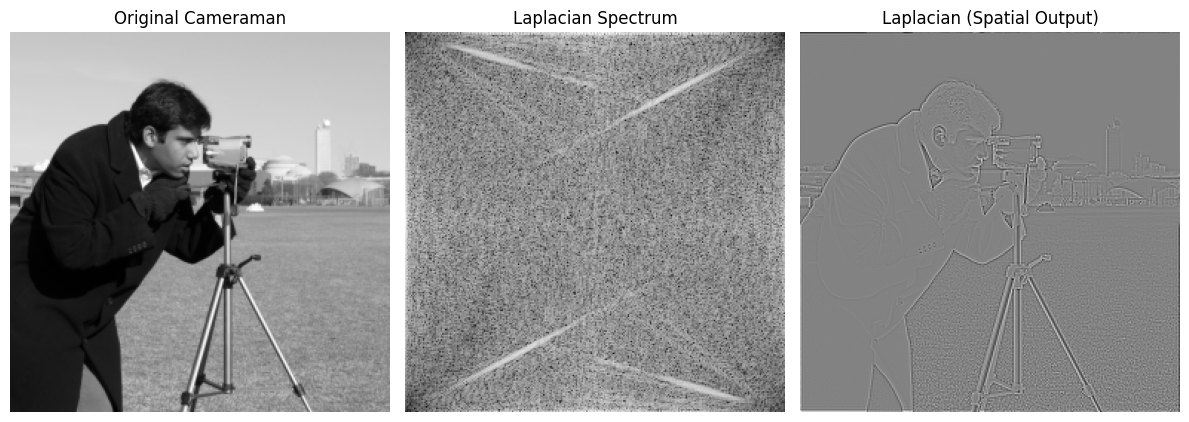

In [3]:
# Load cameraman image (already grayscale)
image = io.imread(CAMERAMAN_PATH)
image = resize(image, (256, 256))  # Resize for faster FFT (optional)
# Get image size
M, N = image.shape
# Generate frequency grid (in fft2 order: DC at index 0)
u = np.fft.fftfreq(M).reshape(-1, 1)
v = np.fft.fftfreq(N).reshape(1, -1)
# Compute Laplacian filter in frequency domain
laplacian_filter = -4 * (np.pi ** 2) * (u**2 + v**2)
# Apply 2D FFT
F = np.fft.fft2(image)
# Apply Laplacian filter in frequency domain
F_lap = F * laplacian_filter
# Inverse FFT to get spatial result
laplacian_image = np.fft.ifft2(F_lap).real
# Plot results
plt.figure(figsize=(12, 5))
plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray')
plt.title('Original Cameraman')
plt.axis('off')
plt.subplot(1, 3, 2)
plt.imshow(np.log(1 + np.abs(F_lap)), cmap='gray')
plt.title('Laplacian Spectrum')
plt.axis('off')
plt.subplot(1, 3, 3)
plt.imshow(laplacian_image, cmap='gray')
plt.title('Laplacian (Spatial Output)')
plt.axis('off')
plt.tight_layout()
plt.show()

The spectrum above is in `fft2` order, so the low frequencies sit in the four
corners. `fftshift` moves the DC term to the centre, which is the usual way to
display a spectrum. Shown that way, the image spectrum is brightest in the
centre (most of the energy is at low frequencies), the Laplacian filter is a
dark centre that brightens outwards, and their product has the centre
suppressed: the low frequencies are removed.

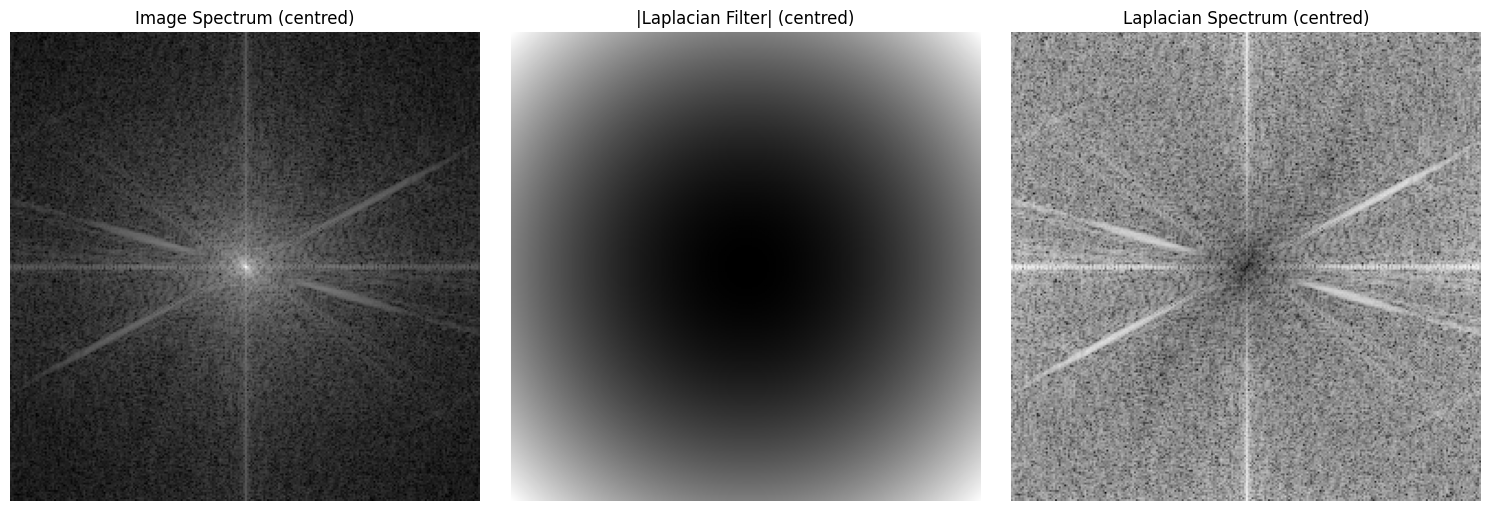

Filter at DC: 0.0
Mean of Laplacian output: 6.51e-19  (DC removed)


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5), layout="constrained")
ax[0].imshow(np.log(1 + np.abs(fftshift(F))), cmap="gray")
ax[0].set_title("Image Spectrum (centred)")
ax[1].imshow(fftshift(np.abs(laplacian_filter)), cmap="gray")
ax[1].set_title("|Laplacian Filter| (centred)")
ax[2].imshow(np.log(1 + np.abs(fftshift(F_lap))), cmap="gray")
ax[2].set_title("Laplacian Spectrum (centred)")
for a in ax:
    a.axis("off")
plt.show()

print(f"Filter at DC: {abs(laplacian_filter[0, 0]):.1f}")
print(f"Mean of Laplacian output: {laplacian_image.mean():.2e}  (DC removed)")

The Laplacian output is close to zero in flat areas (sky, coat) and large
along edges (the camera, the tripod, the man's outline). Because the DC
component is removed, its mean is 0.

### Sharpening with the frequency-domain Laplacian

As in Lab 5, subtracting the Laplacian from the image sharpens it. Here that
becomes a single filter in the frequency domain, `H_sharp = 1 - c * H_lap`,
which passes the low frequencies unchanged and boosts the high ones. `c` is
chosen so the strongest Laplacian response is about as large as the image
range.

c = 0.491


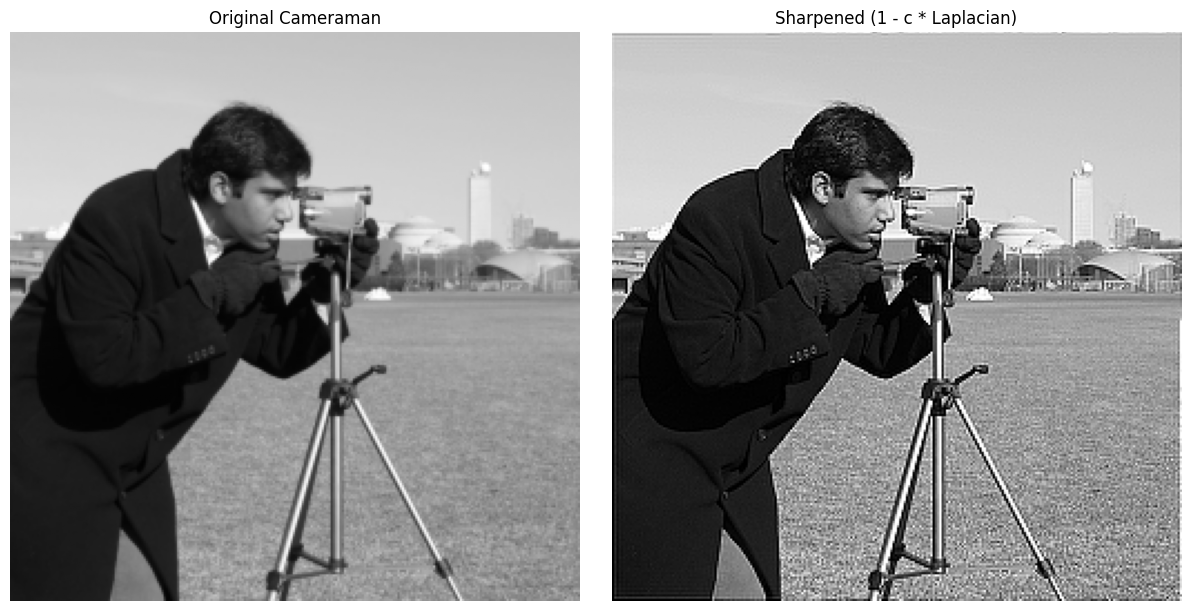

In [5]:
c = 1 / np.abs(laplacian_image).max()
sharp_filter = 1 - c * laplacian_filter
sharpened = np.clip(np.fft.ifft2(F * sharp_filter).real, 0, 1)

print(f"c = {c:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 6), layout="constrained")
ax[0].imshow(image, cmap="gray", vmin=0, vmax=1)
ax[0].set_title("Original Cameraman")
ax[1].imshow(sharpened, cmap="gray", vmin=0, vmax=1)
ax[1].set_title("Sharpened (1 - c * Laplacian)")
for a in ax:
    a.axis("off")
plt.show()

The sharpened image has crisper edges on the camera, tripod and buildings, and
more visible grass texture. The thin lines along the image borders come from
the FFT treating the image as periodic: the left edge is filtered as if it
touched the right edge, and the top as if it touched the bottom.

## Assessment

### Task#1: Sobel filters in the frequency domain

The Sobel kernels approximate the first derivative: `sobel_x` responds to
horizontal changes in intensity (vertical edges) and `sobel_y` to vertical
changes (horizontal edges).

To use a 3x3 kernel in the frequency domain, its FFT has to be the same size as
the image's. `center_embed_kernel` (from the manual's hints) does this:

1. Places the kernel in the centre of a zero array the size of the image.
2. `ifftshift` moves that centre to index (0, 0), which is where `fft2`
   expects the origin of a filter to be. Without it the output would be
   circularly shifted by half the image.
3. Takes `fft2` of the result, giving the filter's frequency response `H`.

Multiplying `F . H` and taking `ifft2` is a circular **convolution** of the
image with the kernel.

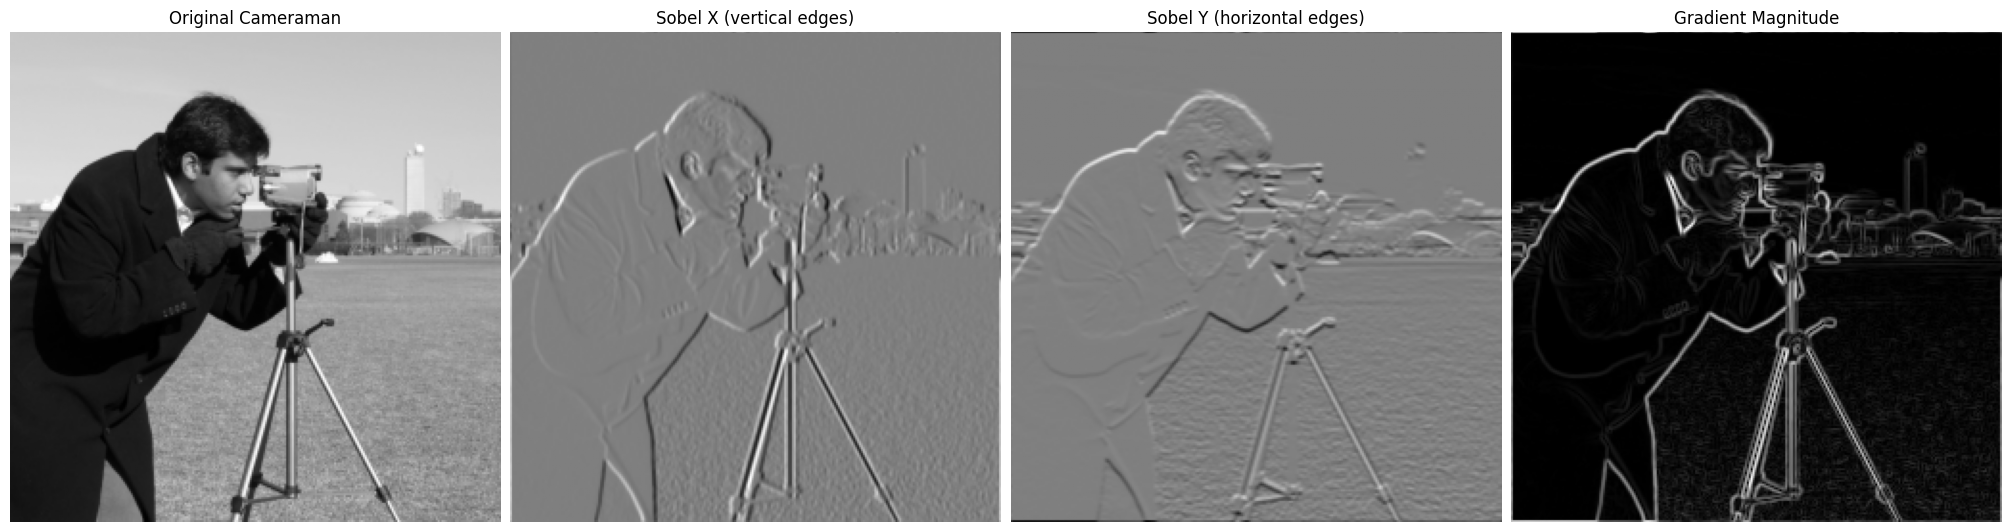

In [6]:
# Load and resize image
image = io.imread(CAMERAMAN_PATH)
image = resize(image, (256, 256))

# Sobel filters
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])
sobel_y = np.array([[-1, -2, -1],
                    [ 0,  0,  0],
                    [ 1,  2,  1]])

# Proper padding and centering of kernel in spatial domain
def center_embed_kernel(kernel, shape):
    padded = np.zeros(shape)
    kh, kw = kernel.shape
    ph, pw = shape
    # Find center coordinates
    cy, cx = ph // 2, pw // 2
    # Insert kernel centered at the image center
    padded[cy - kh//2:cy - kh//2 + kh, cx - kw//2:cx - kw//2 + kw] = kernel
    return fft2(ifftshift(padded))  # Shift before FFT to place (0,0) at top-left

# Compute FFT of image
F = fft2(image)

# FFT of centered Sobel filters (use the provided function)
H_x = center_embed_kernel(sobel_x, image.shape)
H_y = center_embed_kernel(sobel_y, image.shape)

# Multiply in the frequency domain
G_x = ifft2(F * H_x).real
G_y = ifft2(F * H_y).real
magnitude = np.hypot(G_x, G_y)

# Plot
# Gx and Gy are signed, so show them centred on 0 (gray = 0, dark = negative, bright = positive).
lim = max(np.abs(G_x).max(), np.abs(G_y).max())

fig, ax = plt.subplots(1, 4, figsize=(20, 5.5), layout="constrained")
ax[0].imshow(image, cmap="gray")
ax[0].set_title("Original Cameraman")
ax[1].imshow(G_x, cmap="gray", vmin=-lim, vmax=lim)
ax[1].set_title("Sobel X (vertical edges)")
ax[2].imshow(G_y, cmap="gray", vmin=-lim, vmax=lim)
ax[2].set_title("Sobel Y (horizontal edges)")
ax[3].imshow(magnitude, cmap="gray")
ax[3].set_title("Gradient Magnitude")
for a in ax:
    a.axis("off")
plt.show()

`Sobel X` lights up along vertical structures such as the tripod legs and the
man's back, and is nearly flat along the horizon. `Sobel Y` is the opposite:
it picks out the horizon, the shoulders and the top of the camera. The
gradient magnitude `sqrt(Gx^2 + Gy^2)` combines both into a single
edge map.

The frequency responses of the two filters show why. `|H_x|` is zero along the
vertical axis (u = 0, no change across x) and largest at mid horizontal
frequencies; `|H_y|` is the same rotated by 90 degrees. Both are 0 at the DC term,
since each kernel sums to 0, so like the Laplacian they remove flat regions.

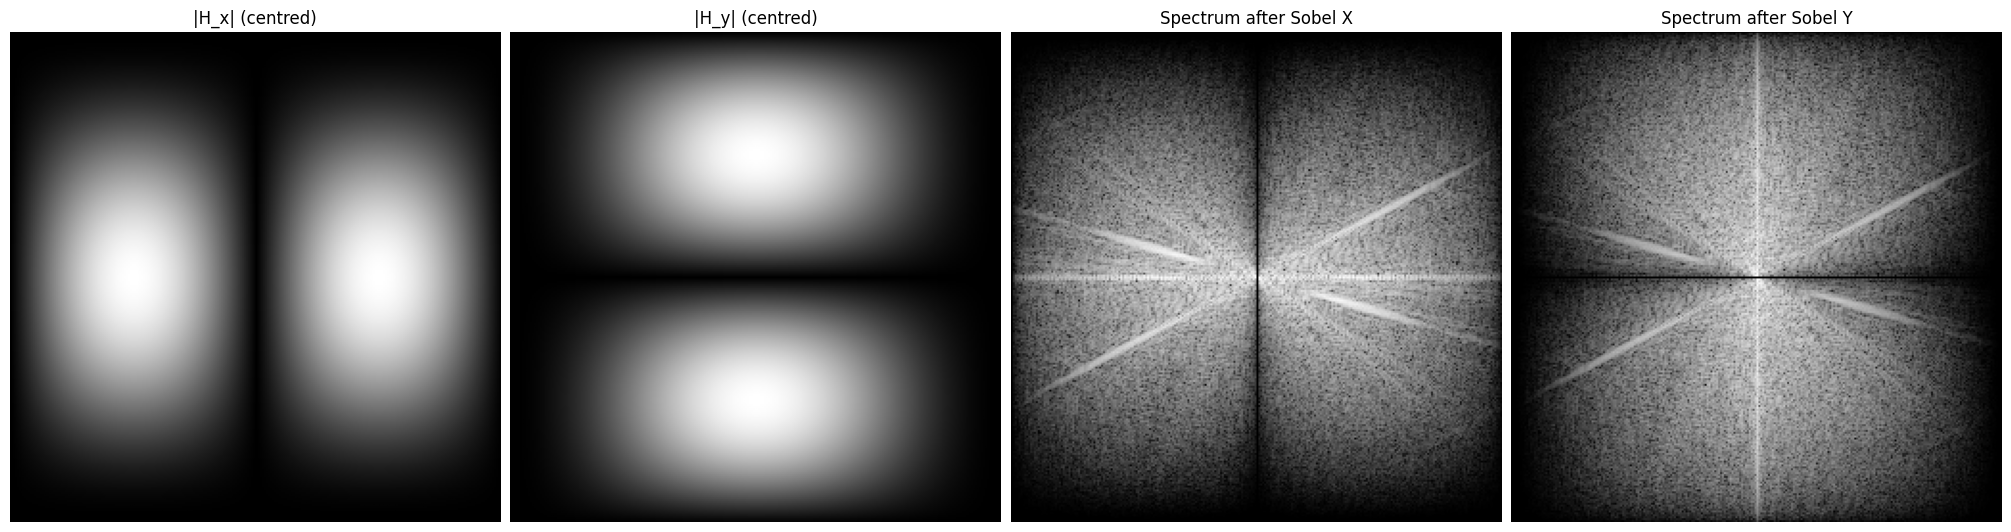

|H_x| at DC: 0.00e+00,  |H_y| at DC: 0.00e+00


In [7]:
fig, ax = plt.subplots(1, 4, figsize=(20, 5.5), layout="constrained")
ax[0].imshow(fftshift(np.abs(H_x)), cmap="gray")
ax[0].set_title("|H_x| (centred)")
ax[1].imshow(fftshift(np.abs(H_y)), cmap="gray")
ax[1].set_title("|H_y| (centred)")
ax[2].imshow(np.log(1 + np.abs(fftshift(F * H_x))), cmap="gray")
ax[2].set_title("Spectrum after Sobel X")
ax[3].imshow(np.log(1 + np.abs(fftshift(F * H_y))), cmap="gray")
ax[3].set_title("Spectrum after Sobel Y")
for a in ax:
    a.axis("off")
plt.show()

print(f"|H_x| at DC: {abs(H_x[0, 0]):.2e},  |H_y| at DC: {abs(H_y[0, 0]):.2e}")

#### Checking against spatial-domain filtering

If the frequency-domain filtering is right, it must give the same result as
convolving in the spatial domain. Multiplying FFTs is a *circular*
convolution (the image wraps around at its borders), so the spatial version
uses `ndimage.convolve` with `mode="wrap"`. The two should agree to
floating-point precision.

Note that this is convolution, which flips the kernel. `cv2.filter2D` (used in
Lab 5) computes correlation instead, which does not flip it, so its Sobel
outputs would have the opposite sign. The edge magnitude is the same either
way.

In [8]:
for name, kernel, G in [("Sobel X", sobel_x, G_x), ("Sobel Y", sobel_y, G_y)]:
    spatial = ndimage.convolve(image, kernel, mode="wrap")
    print(f"{name}: max |frequency - spatial| = {np.abs(G - spatial).max():.2e}, "
          f"match = {np.allclose(G, spatial)}")

Sobel X: max |frequency - spatial| = 1.78e-15, match = True
Sobel Y: max |frequency - spatial| = 2.96e-15, match = True


## Resources

- <https://numpy.org/doc/stable/reference/routines.fft.html>
- <https://docs.opencv.org/4.x/de/dbc/tutorial_py_fourier_transform.html>